# Dyson supplier landscape: YETI shipment analysis

Exploratory analysis of the saved YETI shipment records in `data/raw_yeti_response/`. It answers:

1. **Who** are Dyson's most important suppliers?
2. **How much** do they ship, and how concentrated is the supplier base?
3. **Where** are they located?
4. **What** do they ship, and how has activity changed over time?

> **Coverage caveat:** the records are the pages saved in the repository, not necessarily the full API population. Counts are *saved shipment records*, not complete shipment volumes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import plotly.express as px

PALETTE = ["#1F3A5F", "#2E6F9E", "#4C9BC9", "#8FC1E3", "#C9DFF0"]
ACCENT = "#C0392B"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True, "font.size": 10,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)

DATA_DIR = next(p for p in (Path("data/raw_yeti_response"), Path("../data/raw_yeti_response")) if p.is_dir()).resolve()

In [2]:
rows = []
for path in sorted(DATA_DIR.glob("*.json")):
    for response in json.loads(path.read_text(encoding="utf-8")):
        for rec in response["data"]["data"]:
            rows.append({**rec, "_source_file": path.name})
df = pd.DataFrame(rows)

df["arrival"] = pd.to_datetime(df["arrival_date"], format="mixed", errors="coerce")
df["supplier"] = df["supplier_basename"].fillna(df["supplier_name"])
df["supplier_ctry"] = df["supplier_address_country"].fillna(df["supplier_country"])
df["weight_kg"] = pd.to_numeric(df.get("weight"), errors="coerce")
df["teu_num"] = pd.to_numeric(df.get("teu"), errors="coerce")
loc = df["supplier_address_geocode"].apply(lambda g: g.get("location", {}) if isinstance(g, dict) else {})
df["lat"] = loc.apply(lambda d: d.get("lat"))
df["lon"] = loc.apply(lambda d: d.get("lon"))

# The same shipment can be saved by more than one query; keep it once.
before = len(df)
df = df.drop_duplicates(subset=["bol_number", "supplier", "hs_code", "arrival_date"]).reset_index(drop=True)

by_supplier = (df.groupby("supplier")
               .agg(shipments=("supplier", "size"), country=("supplier_ctry", lambda s: s.mode().iat[0] if s.notna().any() else None),
                    first_seen=("arrival", "min"), last_seen=("arrival", "max"),
                    teu=("teu_num", "sum"), weight_kg=("weight_kg", "sum"))
               .sort_values("shipments", ascending=False))
by_supplier["share_pct"] = 100 * by_supplier["shipments"] / by_supplier["shipments"].sum()
by_supplier["cum_share_pct"] = by_supplier["share_pct"].cumsum()

In [3]:
top = by_supplier.iloc[0]
hhi = ((by_supplier["share_pct"] / 100) ** 2).sum() * 10_000
kpis = pd.DataFrame({
    "Metric": ["Buyer", "Shipment records (unique)", "Distinct suppliers", "Supplier countries",
               "Top supplier", "Top-3 supplier share", "Concentration (HHI)", "Arrival window"],
    "Value": [df["company_basename"].mode().iat[0], f"{len(df):,}  ({before - len(df):,} duplicates removed)",
              f"{by_supplier.shape[0]}", f"{df['supplier_ctry'].nunique()}",
              f"{top.name} ({top.share_pct:.1f}%)", f"{by_supplier['share_pct'].head(3).sum():.1f}%",
              f"{hhi:,.0f}  (<1,500 diversified, >2,500 concentrated)",
              f"{df['arrival'].min():%b %Y} to {df['arrival'].max():%b %Y}"],
})
kpis.style.hide(axis="index").set_properties(**{"text-align": "left"})

Metric,Value
Buyer,Dyson
Shipment records (unique),448 (31 duplicates removed)
Distinct suppliers,10
Supplier countries,7
Top supplier,Ihastek Malaysia (15.4%)
Top-3 supplier share,39.1%
Concentration (HHI),"1,068 (<1,500 diversified, >2,500 concentrated)"
Arrival window,Jan 2025 to Sep 2026


## 1. Top suppliers by shipment count

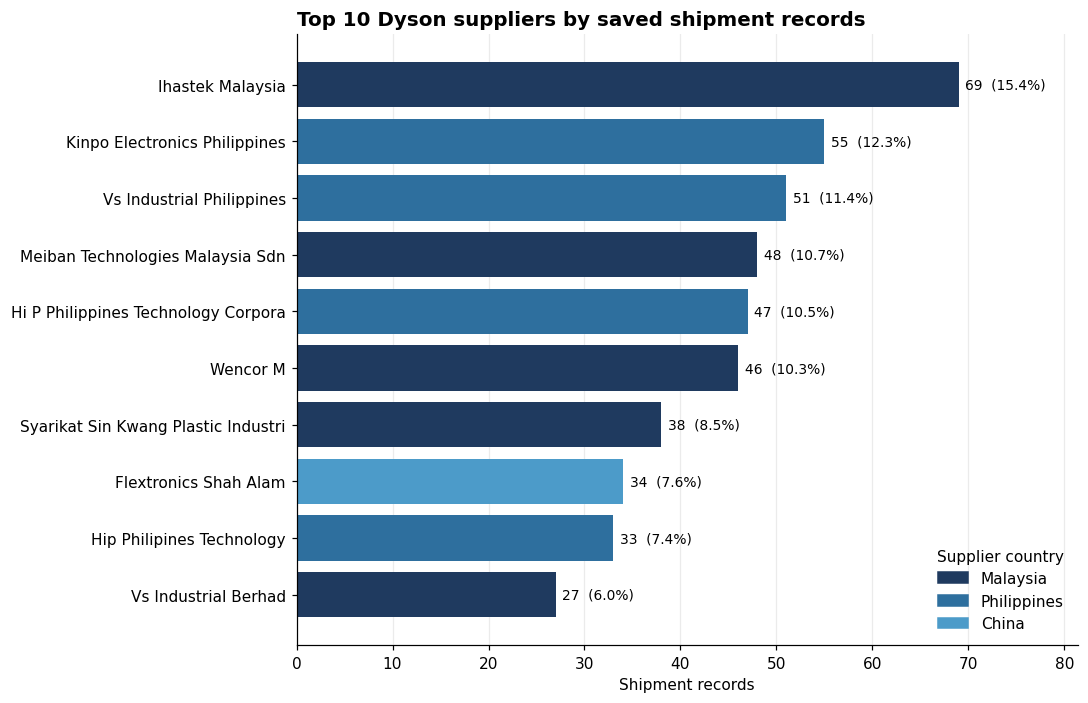

In [4]:
n = min(12, len(by_supplier))
top_n = by_supplier.head(n).iloc[::-1]
ctry_colors = {c: PALETTE[i % len(PALETTE)] for i, c in enumerate(by_supplier["country"].dropna().unique())}

fig, ax = plt.subplots(figsize=(10, 0.5 * n + 1.5))
bars = ax.barh(top_n.index, top_n["shipments"], color=[ctry_colors[c] for c in top_n["country"]])
for b, (_, r) in zip(bars, top_n.iterrows()):
    ax.text(b.get_width() + top_n["shipments"].max() * .01, b.get_y() + b.get_height() / 2,
            f"{int(r.shipments)}  ({r.share_pct:.1f}%)", va="center", fontsize=9)
ax.set_xlim(0, top_n["shipments"].max() * 1.18)
ax.set_title(f"Top {n} Dyson suppliers by saved shipment records")
ax.set_xlabel("Shipment records")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ctry_colors.values()],
          labels=ctry_colors.keys(), title="Supplier country", loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

## 2. Supplier concentration

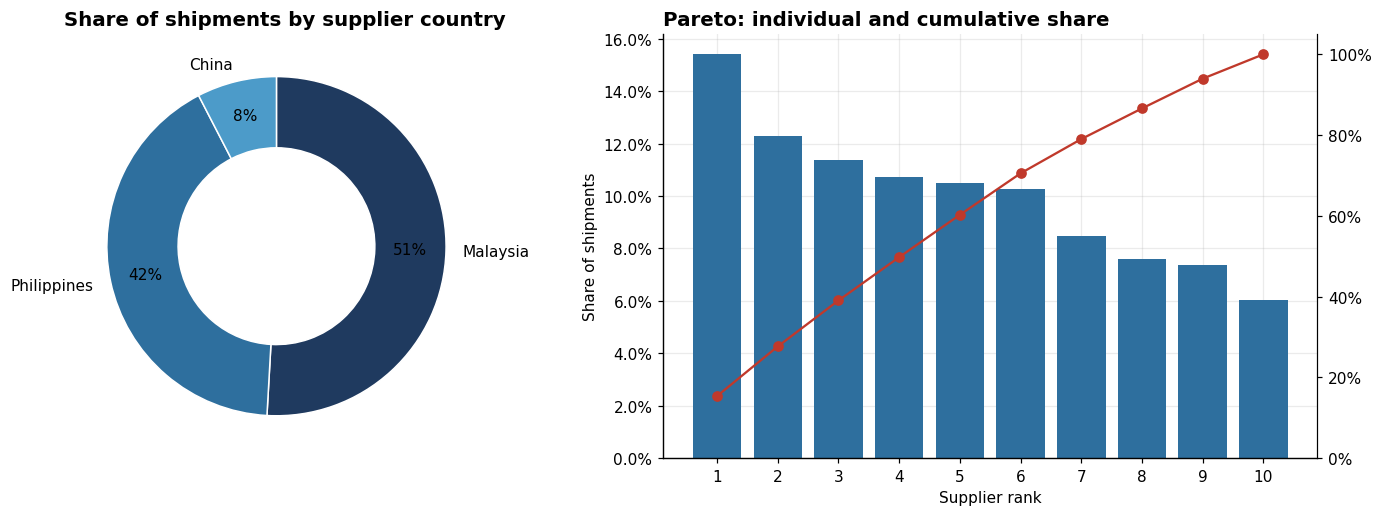

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})

c = by_supplier.groupby("country")["shipments"].sum().sort_values(ascending=False)
a1.pie(c, labels=c.index, autopct="%1.0f%%", startangle=90, counterclock=False, colors=PALETTE + [ACCENT],
       wedgeprops={"width": .42, "edgecolor": "white"}, pctdistance=.79)
a1.set_title("Share of shipments by supplier country")

p = by_supplier.head(n)
a2.bar(range(1, n + 1), p["share_pct"], color=PALETTE[1])
a2.set_ylabel("Share of shipments")
a2.yaxis.set_major_formatter(mtick.PercentFormatter())
a3 = a2.twinx()
a3.plot(range(1, n + 1), p["cum_share_pct"], color=ACCENT, marker="o")
a3.set_ylim(0, 105); a3.yaxis.set_major_formatter(mtick.PercentFormatter()); a3.grid(False)
a3.spines["right"].set_visible(True)
a2.set_xticks(range(1, n + 1)); a2.set_xlabel("Supplier rank")
a2.set_title("Pareto: individual and cumulative share")
plt.tight_layout()
plt.show()

## 3. Where are the suppliers located?

In [6]:
geo = (df.dropna(subset=["lat", "lon"])
       .groupby(["supplier", "supplier_ctry", "lat", "lon"]).size().rename("shipments").reset_index())
fig = px.scatter_geo(geo, lat="lat", lon="lon", size="shipments", color="supplier_ctry", hover_name="supplier",
                     hover_data={"lat": False, "lon": False, "shipments": True}, size_max=40,
                     color_discrete_sequence=PALETTE[:3] + [ACCENT, "#E39B2D"],
                     title="Supplier locations (bubble size = shipment records)")
fig.update_geos(fitbounds="locations", showcountries=True, countrycolor="#BBBBBB", showland=True,
                landcolor="#F4F4F4", showocean=True, oceancolor="#E8F1F8", projection_type="natural earth")
fig.update_layout(height=520, margin=dict(l=0, r=0, t=50, b=0), legend_title="Country")
fig.show()
print("Note: geocodes in this feed often resolve to a country centroid, not the facility; treat as country-level.")

Note: geocodes in this feed often resolve to a country centroid, not the facility; treat as country-level.


In [7]:
loc_table = (by_supplier.reset_index()[["supplier", "country", "shipments", "share_pct"]]
             .merge(df.drop_duplicates("supplier")[["supplier", "supplier_address"]], on="supplier", how="left")
             .rename(columns={"supplier": "Supplier", "country": "Country", "shipments": "Shipments",
                              "share_pct": "Share %", "supplier_address": "Reported address"}))
loc_table["Reported address"] = loc_table["Reported address"].str.title().str.slice(0, 90)
loc_table.head(15).style.hide(axis="index").format({"Share %": "{:.1f}%"})

Supplier,Country,Shipments,Share %,Reported address
Ihastek Malaysia,Malaysia,69,15.4%,Plo 39 Jalan Persiaran Teknologi Taman Teknologi Johor Senai My 60187784113 Wahidah_Noor I
Kinpo Electronics Philippines,Philippines,55,12.3%,Lot 11 H Y Dimacali Avenue Fpip Ii-Sez Brgy Sta Anastacia City Of Sto Tomas Ph 63432338888
Vs Industrial Philippines,Philippines,51,11.4%,Street Light Industry And Science Park Iii San Rafael City Of Sto Tomas Santo Tomas Ph
Meiban Technologies Malaysia Sdn,Malaysia,48,10.7%,20 22 & 24 Jalan Istimewa 7 Taman Perindustrian Cemerlang Ulu Tiram My 6078625111
Hi P Philippines Technology Corpora,Philippines,47,10.5%,Bldg X2 Lot 11A Phase 1B First Phil Ippine Industrial Park - Special Economic Zone City Of
Wencor M,Malaysia,46,10.3%,No 2 Jalan Selatan 11 Kawasan Peri Johor Bahru Na 81300 My 6075112750 Forwarder Billing We
Syarikat Sin Kwang Plastic Industri,Malaysia,38,8.5%,421 4Th Miles Jalan Kluang Batu Pahat My 6075980000
Flextronics Shah Alam,China,34,7.6%,Plot D26 Jalan Dpb/4 Kawasan Zon Perindustrian Bebas Pelabuhan Tanjung Pelepas Gelang Pata
Hip Philipines Technology,Philippines,33,7.4%,Bldg X2 Lot 11A Phase 1B In Fpipsez Tanauan Na 6502 Ph 639175451830 Sharlene Malabanan Hi
Vs Industrial Berhad,Malaysia,27,6.0%,Ptd 102246 Jalan Murni 12 Kawasan P Senai Na 81400 My 6075973399 Vs18Shipping Vs I Com


## 4. Activity over time

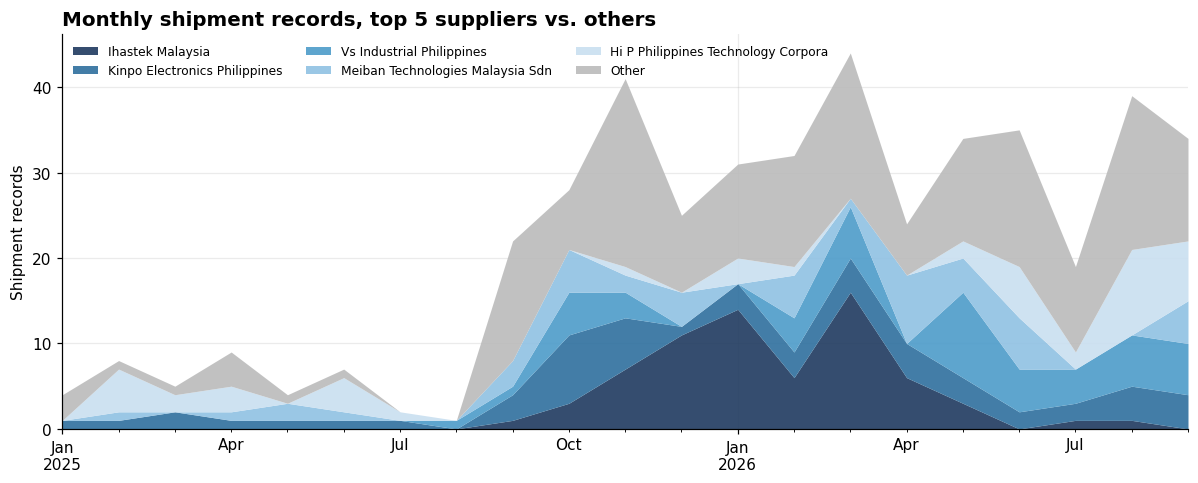

In [8]:
monthly = (df.dropna(subset=["arrival"]).assign(m=lambda d: d["arrival"].dt.to_period("M").dt.to_timestamp())
           .pivot_table(index="m", columns="supplier", values="bol_number", aggfunc="size", fill_value=0))
keep = by_supplier.head(5).index
plot = monthly[keep].assign(Other=monthly.drop(columns=keep).sum(axis=1))

ax = plot.plot.area(figsize=(11, 4.5), color=PALETTE + ["#BBBBBB"], linewidth=0, alpha=.9)
ax.set(title="Monthly shipment records, top 5 suppliers vs. others", xlabel="", ylabel="Shipment records")
ax.legend(loc="upper left", ncol=3, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 5. Trade lanes and products

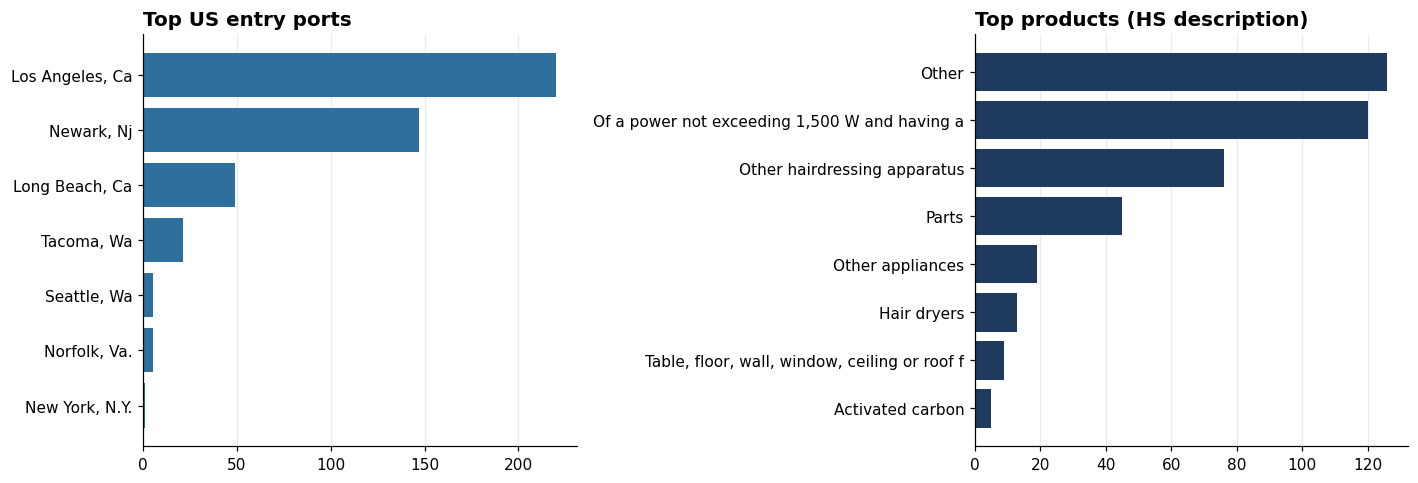

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
ports = df["entry_port"].value_counts().head(8).iloc[::-1]
a1.barh(ports.index, ports.values, color=PALETTE[1]); a1.set_title("Top US entry ports"); a1.grid(axis="y", visible=False)
prod = df["hs_code_description"].fillna("Unspecified").str.slice(0, 45).value_counts().head(8).iloc[::-1]
a2.barh(prod.index, prod.values, color=PALETTE[0]); a2.set_title("Top products (HS description)"); a2.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [10]:
lane = (df.groupby(["supplier_ctry", "exit_port"]).size().rename("shipments").reset_index()
        .sort_values("shipments", ascending=False).head(10)
        .rename(columns={"supplier_ctry": "Supplier country", "exit_port": "Exit port", "shipments": "Shipments"}))
lane.style.hide(axis="index")

Supplier country,Exit port,Shipments
Malaysia,Tanjung Pelepas,117
Philippines,Manila,59
Singapore,Singapore,41
Philippines,Shanghai,31
China,Shanghai,27
China,Yangshan,25
Philippines,Kaohsiung,20
Malaysia,Port Klang,14
Philippines,Pusan,13
Philippines,Nansha,13


## 6. Key takeaways and next steps

- Read the top-supplier chart and Pareto for concentration: a small group of suppliers in one or two countries drives most records.
- Country-level concentration (donut and map) shows geographic risk exposure.
- Next: normalise supplier names that appear under multiple entities (for example the Flextronics and Ihastek variants), recover missing API pages, and promote the supplier → Dyson links into the knowledge graph.